# Model training

- Linear Regression
- Decision Tree
- Random Forest
- KNN
- SVR

Plus a mean-prediction baseline for context.


In [1]:
# import libraries

import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, plot_tree

import matplotlib
matplotlib.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

# Paths

PROC = pathlib.Path('../data/processed/red_wine_cleaned.csv')
OUT = pathlib.Path('../data/outputs')
ASSETS = pathlib.Path('../assets/images')
ASSETS.mkdir(parents=True, exist_ok=True)


In [2]:
df = pd.read_csv(PROC)
df.head()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


### Common training steps for all models


In [3]:
X = df.drop(columns=['quality'])
y = df['quality']

num_cols = list(X.columns)
num_pipe = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
pre = ColumnTransformer([('num', num_pipe, num_cols)])

print(num_cols)


['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train {X_train.shape}, Test {X_test.shape} - mean quality train {y_train.mean():.2f}")


Train (1087, 11), Test (272, 11) - mean quality train 5.64


In [5]:
cv = KFold(5, shuffle=True, random_state=42)
scoring = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}

test_preds = {}


def make_pipe(model):
    return Pipeline([('pre', pre), ('model', model)])


def cv_scores(pipe):
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    return {
        'CV_RMSE': -s['test_rmse'].mean(),
        'CV_RMSE_std': s['test_rmse'].std(),
        'CV_MAE': -s['test_mae'].mean(),
        'CV_R2': s['test_r2'].mean(),
        'CV_R2_std': s['test_r2'].std(),
    }


def test_scores(pipe):
    pred = pipe.predict(X_test)
    return pred, {
        'test_RMSE': float(np.sqrt(mean_squared_error(y_test, pred))),
        'test_MAE': mean_absolute_error(y_test, pred),
        'test_R2': r2_score(y_test, pred),
    }


def print_cv(cv_res):
    print(f"CV RMSE: {cv_res['CV_RMSE']:.3f} (+/- {cv_res['CV_RMSE_std']:.3f})")
    print(f"CV MAE:  {cv_res['CV_MAE']:.3f}")
    print(f"CV R2:   {cv_res['CV_R2']:.3f} (+/- {cv_res['CV_R2_std']:.3f})")


def print_scores(cv_res, ts_res):
    print(f"CV RMSE: {cv_res['CV_RMSE']:.3f} (+/- {cv_res['CV_RMSE_std']:.3f})")
    print(f"CV MAE:  {cv_res['CV_MAE']:.3f}")
    print(f"CV R2:   {cv_res['CV_R2']:.3f} (+/- {cv_res['CV_R2_std']:.3f})")
    print(f"Test RMSE: {ts_res['test_RMSE']:.3f}   Test MAE: {ts_res['test_MAE']:.3f}   Test R2: {ts_res['test_R2']:.3f}")


def plot_diagnostics(name, pred, save=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    lo = min(y_test.min(), pred.min()) - 0.5
    hi = max(y_test.max(), pred.max()) + 0.5
    axes[0].scatter(y_test, pred, alpha=0.5, color='#2a9d8f')
    axes[0].plot([lo, hi], [lo, hi], 'r--', label='perfect')
    axes[0].set(xlabel='Actual quality', ylabel='Predicted quality',
                title=f'{name} - predicted vs actual', xlim=(lo, hi), ylim=(lo, hi))
    axes[0].legend()
    sns.histplot(y_test - pred, kde=True, ax=axes[1], color='#e76f51')
    axes[1].axvline(0, color='r', linestyle='--')
    axes[1].set(xlabel='Residual', title=f'{name} - residuals')
    plt.tight_layout()
    if save is not None:
        plt.savefig(save, bbox_inches='tight')
        print(f"Saved {save}")
    plt.show()


### Baseline - always predict the mean


In [6]:
dummy = DummyRegressor(strategy='mean')
pipe_dummy = make_pipe(dummy)
cv_dummy = cv_scores(pipe_dummy)
pipe_dummy.fit(X_train, y_train)
pred_dummy, ts_dummy = test_scores(pipe_dummy)
test_preds['Baseline(mean)'] = pred_dummy
print_scores(cv_dummy, ts_dummy)


CV RMSE: 0.818 (+/- 0.053)
CV MAE:  0.692
CV R2:   -0.011 (+/- 0.009)
Test RMSE: 0.844   Test MAE: 0.705   Test R2: -0.006


### Linear Regression


In [7]:
linear = LinearRegression()
pipe_linear = make_pipe(linear)
cv_linear = cv_scores(pipe_linear)
print(linear)
print_cv(cv_linear)


LinearRegression()
CV RMSE: 0.668 (+/- 0.027)
CV MAE:  0.518
CV R2:   0.321 (+/- 0.054)


CV RMSE: 0.668 (+/- 0.027)
CV MAE:  0.518
CV R2:   0.321 (+/- 0.054)
Test RMSE: 0.657   Test MAE: 0.504   Test R2: 0.392


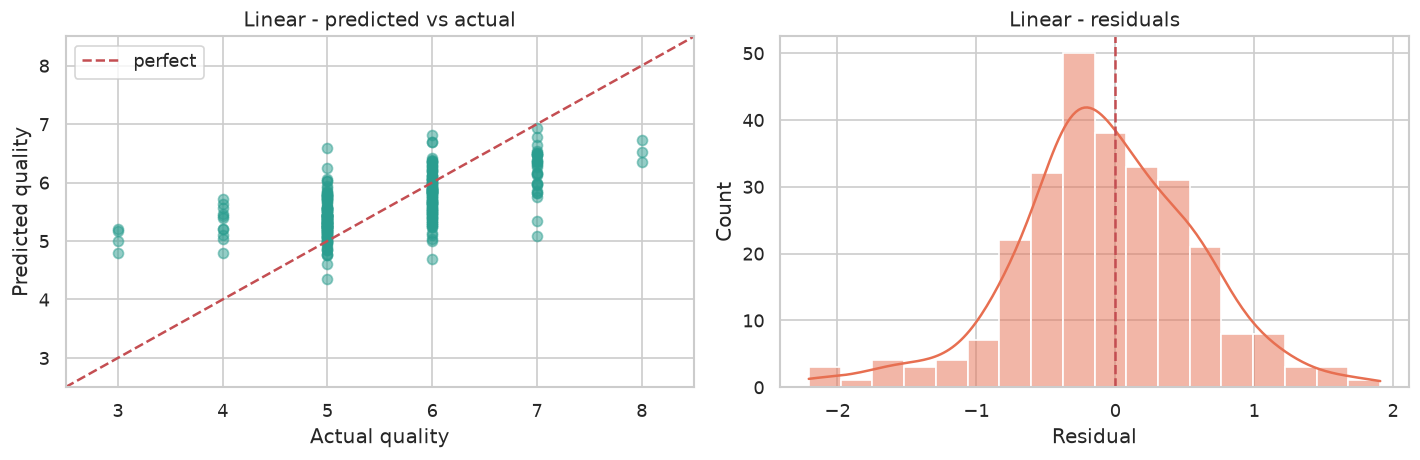

In [8]:
pipe_linear.fit(X_train, y_train)
pred_linear, ts_linear = test_scores(pipe_linear)
test_preds['Linear'] = pred_linear
print_scores(cv_linear, ts_linear)
plot_diagnostics('Linear', pred_linear)


In [9]:
# What did the model learn? Positive coefficient = higher predicted score
coefs = pipe_linear.named_steps['model'].coef_
for name, c in sorted(zip(num_cols, coefs), key=lambda x: x[1], reverse=True):
    print(f"{name:24} {c:+.3f}")
print("\nAlcohol positive and volatile acidity negative - both match the EDA in 02.")


alcohol                  +0.334
sulphates                +0.148
free sulfur dioxide      +0.049
density                  +0.042
residual sugar           -0.005
citric acid              -0.019
fixed acidity            -0.050
chlorides                -0.116
pH                       -0.122
total sulfur dioxide     -0.124
volatile acidity         -0.178

Alcohol positive and volatile acidity negative - both match the EDA in 02.


## Decision Tree


In [10]:
tree = DecisionTreeRegressor(random_state=42, max_depth=6)
pipe_tree = make_pipe(tree)
cv_tree = cv_scores(pipe_tree)
print(tree)
print_cv(cv_tree)


DecisionTreeRegressor(max_depth=6, random_state=42)
CV RMSE: 0.760 (+/- 0.045)
CV MAE:  0.565
CV R2:   0.121 (+/- 0.093)


CV RMSE: 0.760 (+/- 0.045)
CV MAE:  0.565
CV R2:   0.121 (+/- 0.093)
Test RMSE: 0.671   Test MAE: 0.504   Test R2: 0.364


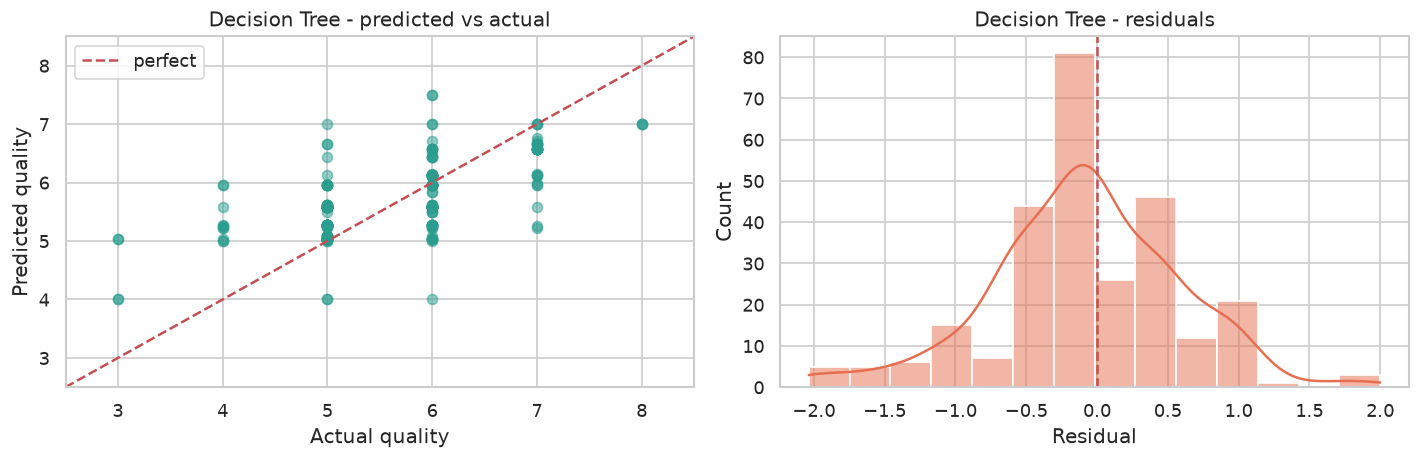

In [11]:
pipe_tree.fit(X_train, y_train)
pred_tree, ts_tree = test_scores(pipe_tree)
test_preds['DecisionTree'] = pred_tree
print_scores(cv_tree, ts_tree)
plot_diagnostics('Decision Tree', pred_tree)


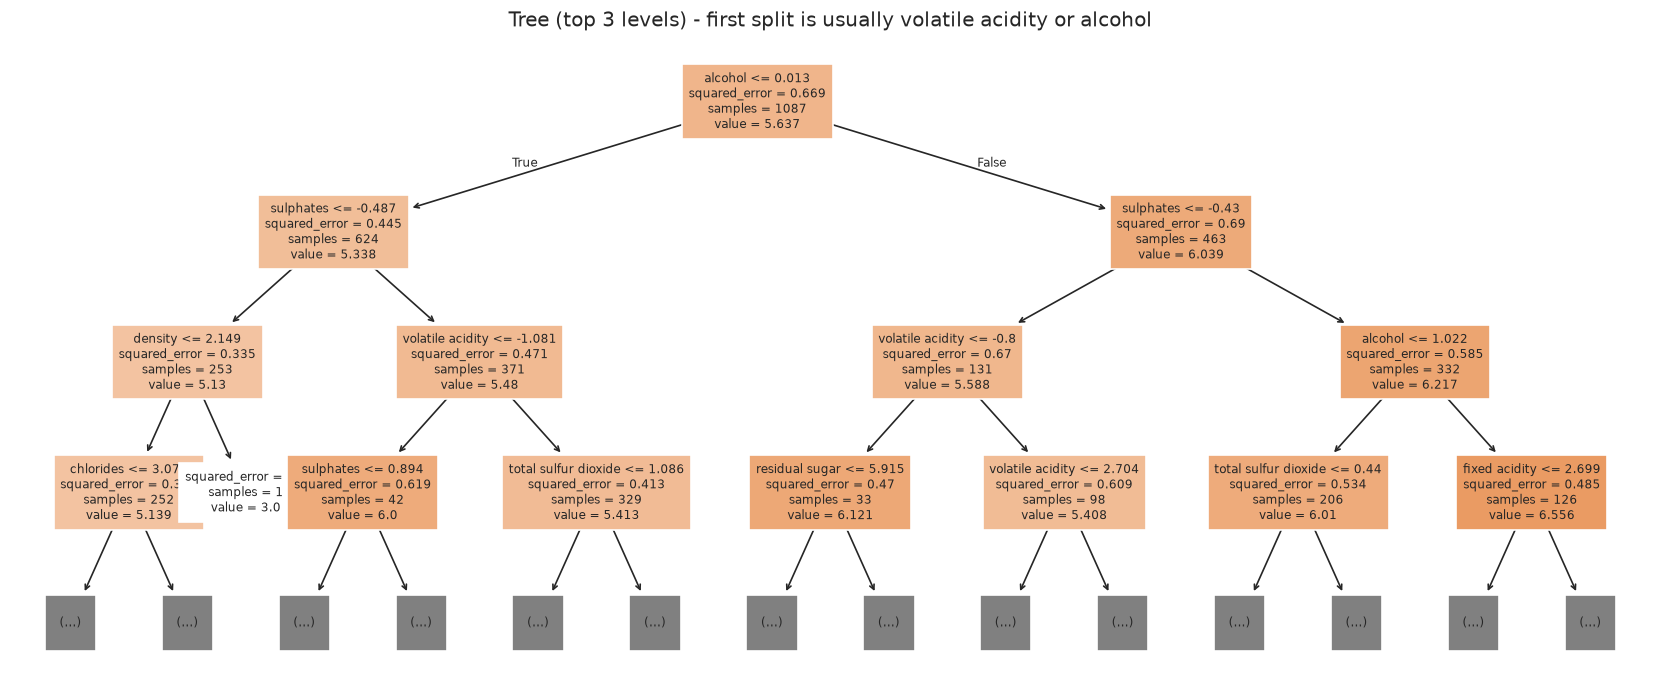

In [12]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(pipe_tree.named_steps['model'], feature_names=num_cols, filled=True,
          max_depth=3, fontsize=7, ax=ax)
ax.set_title('Tree (top 3 levels) - first split is usually volatile acidity or alcohol')
plt.tight_layout()
plt.show()


## K-Nearest Neighbors (K=5)


In [13]:
knn = KNeighborsRegressor(n_neighbors=5)
pipe_knn = make_pipe(knn)
cv_knn = cv_scores(pipe_knn)
print(knn)
print("KNN needs the StandardScaler in 'pre' - otherwise residual sugar dominates density.")


KNeighborsRegressor()
KNN needs the StandardScaler in 'pre' - otherwise residual sugar dominates density.


CV RMSE: 0.713 (+/- 0.041)
CV MAE:  0.543
CV R2:   0.228 (+/- 0.066)
Test RMSE: 0.713   Test MAE: 0.540   Test R2: 0.283


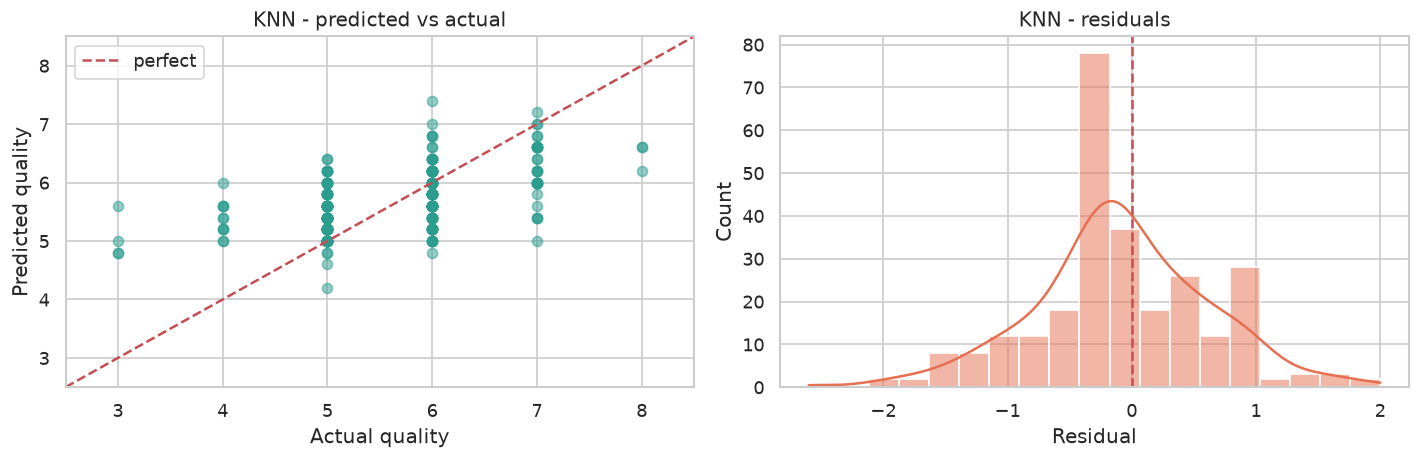

In [14]:
pipe_knn.fit(X_train, y_train)
pred_knn, ts_knn = test_scores(pipe_knn)
test_preds['KNN(k=5)'] = pred_knn
print_scores(cv_knn, ts_knn)
plot_diagnostics('KNN', pred_knn)


## Support Vector Regression (RBF)


In [15]:
svm = SVR(kernel='rbf', C=10, epsilon=0.1, gamma='scale')
pipe_svm = make_pipe(svm)
cv_svm = cv_scores(pipe_svm)
print(svm)
print_cv(cv_svm)


SVR(C=10)
CV RMSE: 0.723 (+/- 0.033)
CV MAE:  0.548
CV R2:   0.206 (+/- 0.059)


CV RMSE: 0.723 (+/- 0.033)
CV MAE:  0.548
CV R2:   0.206 (+/- 0.059)
Test RMSE: 0.692   Test MAE: 0.517   Test R2: 0.323


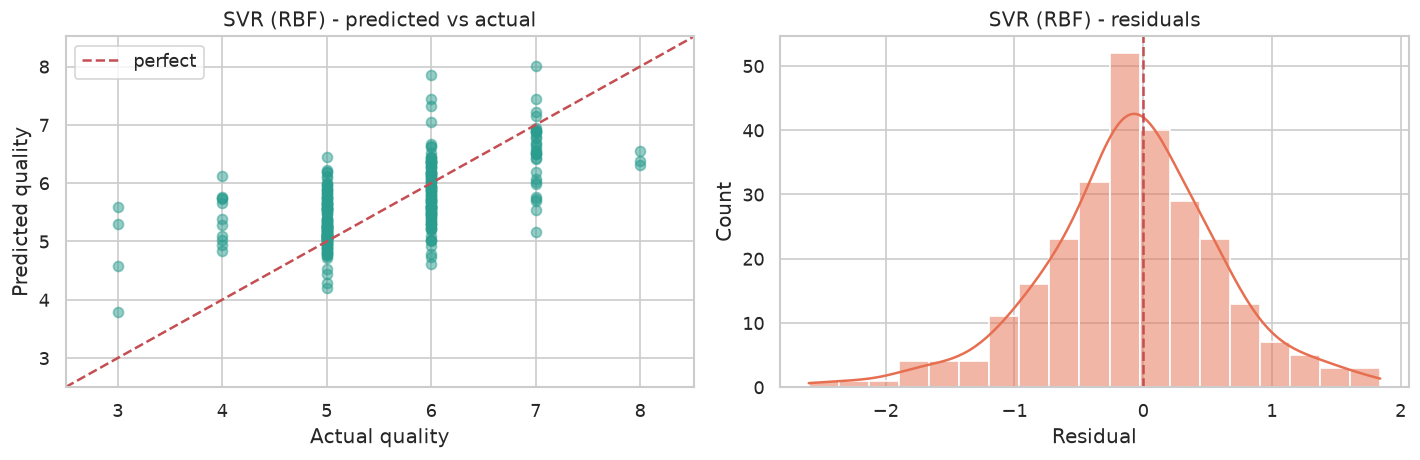

In [16]:
pipe_svm.fit(X_train, y_train)
pred_svm, ts_svm = test_scores(pipe_svm)
test_preds['SVR_rbf'] = pred_svm
print_scores(cv_svm, ts_svm)
plot_diagnostics('SVR (RBF)', pred_svm)


## Random Forest


In [17]:
rf = RandomForestRegressor(n_estimators=200, random_state=42)
pipe_rf = make_pipe(rf)
cv_rf = cv_scores(pipe_rf)
print(rf)
print_cv(cv_rf)


RandomForestRegressor(n_estimators=200, random_state=42)
CV RMSE: 0.658 (+/- 0.030)
CV MAE:  0.507
CV R2:   0.342 (+/- 0.053)


CV RMSE: 0.658 (+/- 0.030)
CV MAE:  0.507
CV R2:   0.342 (+/- 0.053)
Test RMSE: 0.618   Test MAE: 0.468   Test R2: 0.460


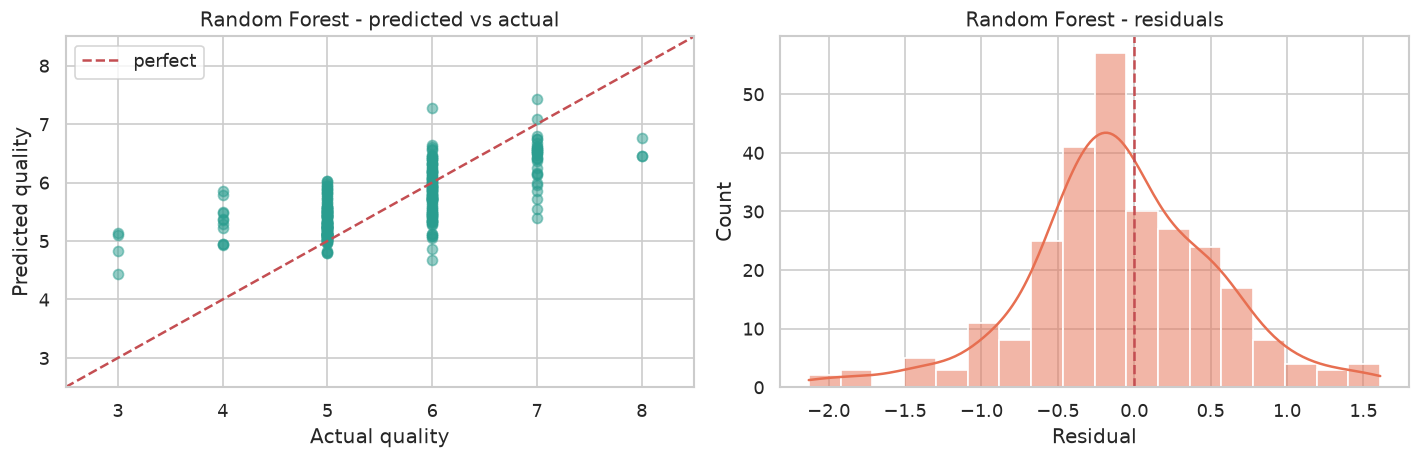

In [18]:
pipe_rf.fit(X_train, y_train)
pred_rf, ts_rf = test_scores(pipe_rf)
test_preds['RandomForest'] = pred_rf
print_scores(cv_rf, ts_rf)
plot_diagnostics('Random Forest', pred_rf)


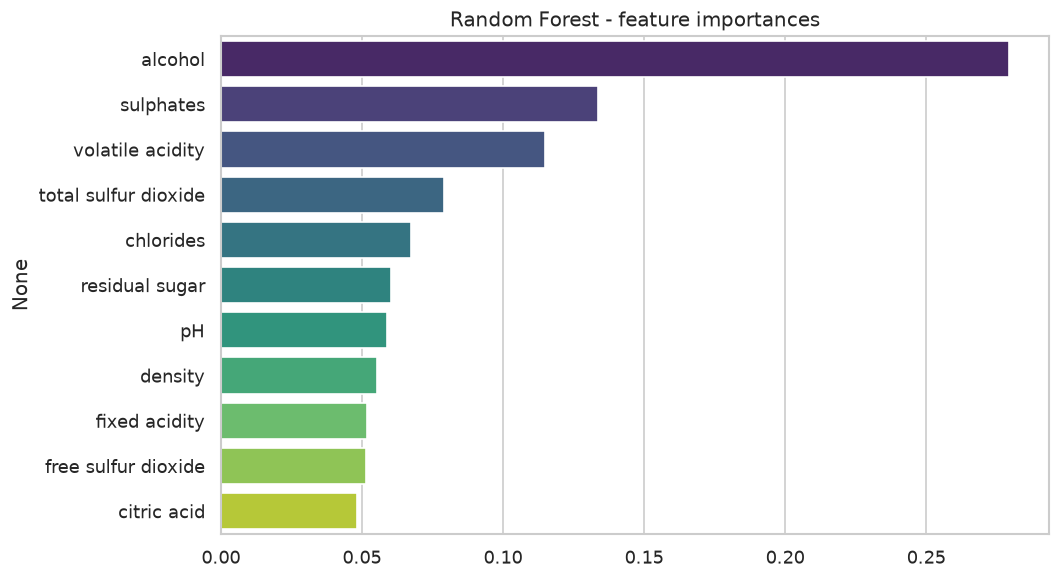

In [19]:
importances = pd.Series(pipe_rf.named_steps['model'].feature_importances_, index=num_cols).sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette='viridis', legend=False)
plt.title('Random Forest - feature importances')
plt.tight_layout()
plt.show()


## Save the model summary for the next notebook


,model,CV_RMSE,CV_R2,test_RMSE,test_R2
5,RandomForest,0.6583,0.3416,0.6182,0.4604
1,Linear,0.6684,0.3209,0.6565,0.3915
3,KNN(k=5),0.7132,0.2276,0.7129,0.2825
4,SVR_rbf,0.7232,0.2057,0.6924,0.3232
2,DecisionTree,0.7604,0.1206,0.6711,0.3643
0,Baseline(mean),0.8179,-0.0108,0.8443,-0.0063


Saved to ../data/outputs/baseline_comparison.csv
Best model by CV R2: RandomForest
Saved ../assets/images/best_model.png


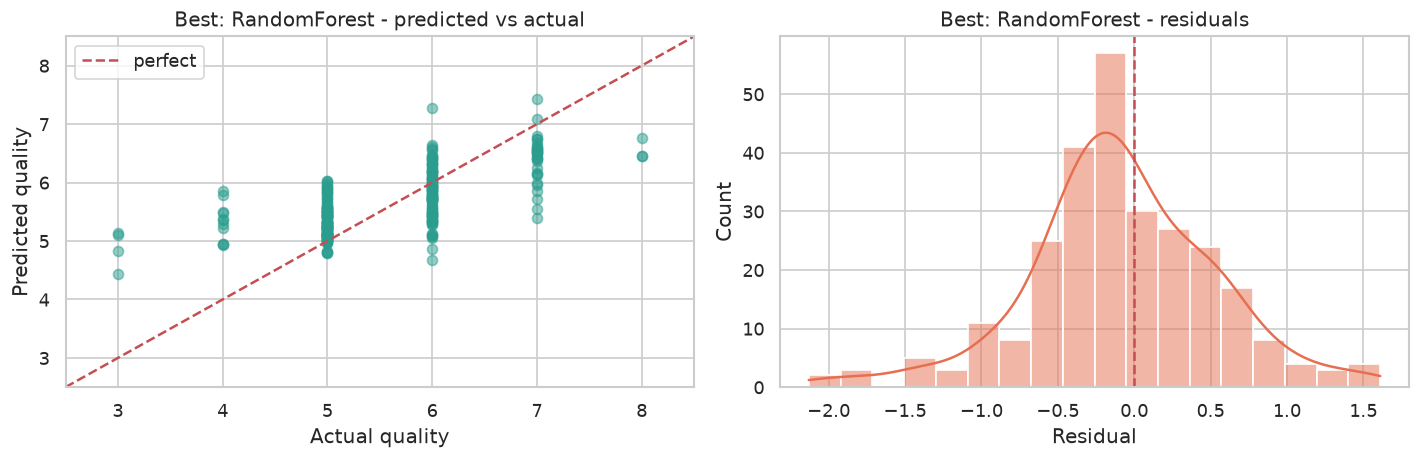

In [20]:
rows = []
for name, cv_res, ts_res in [
    ('Baseline(mean)', cv_dummy, ts_dummy),
    ('Linear', cv_linear, ts_linear),
    ('DecisionTree', cv_tree, ts_tree),
    ('KNN(k=5)', cv_knn, ts_knn),
    ('SVR_rbf', cv_svm, ts_svm),
    ('RandomForest', cv_rf, ts_rf),
]:
    rows.append({'model': name, **cv_res, **ts_res})

comp = pd.DataFrame(rows).sort_values('CV_R2', ascending=False).round(4)
display(comp[['model', 'CV_RMSE', 'CV_R2', 'test_RMSE', 'test_R2']])
comp.to_csv(OUT / 'baseline_comparison.csv', index=False)
print("Saved to ../data/outputs/baseline_comparison.csv")

best = comp[comp['model'] != 'Baseline(mean)'].iloc[0]['model']
print(f"Best model by CV R2: {best}")
plot_diagnostics(f'Best: {best}', test_preds[best], save=ASSETS / 'best_model.png')
